# UMAMI Urban Heat V4 — 23-Channel Multi-Task Training

**Goal:** push beyond V3's RMSE by adding the supervision and inputs V3 couldn't use:
1. **Real Landsat LST labels** — V3 had this head all-NaN; V4 has 9,458 real LST observations
2. **Full ERA5 weather forcing** — V3 had Tair only; V4 adds RH, wind, SSRD
3. **Vegetation density** — Sentinel-2 NDVI raster (the cooling effect of trees vs grass vs concrete)
4. **Time-of-day shadow trajectory** — 3 reference shadows (9 AM / 1 PM / 4 PM Jan 22) for lagged building heating
5. **Roof-type one-hot** — Geoscape Flat / Moderate / Steep distinguishes office canyons from suburban roofs
6. **Solar-panel mask** — modifies effective rooftop albedo where panels are installed

**Inputs (on Drive at `gdrive:UMAMI/urban_heat_v4/`):**
- `patches_v4.tar` — single ~50 GB tar containing 11,844 .npz + manifest.parquet (extracted to `/content/patches_v4/` in cell 1.5 below)
- `models/v21_best.pt` — V3 checkpoint for warm-start (extends first conv 12 → 23, zero-init slots 12-22)

**Output:** `gdrive:UMAMI/urban_heat_v4/models/v4_best.pt` + `umami_unet_v4_fp32.onnx`

**Runtime:** ~4-5 h on a single A100 (slightly slower than V3 due to wider input + active LST head).

## 1 — Setup (Drive mount + dependencies)

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### 1.5 — Extract patches_v4.tar from Drive to local /content

Same pattern as V3: copy + extract once at start so DataLoader hits Colab's local SSD instead of the throttled Drive mount.

In [2]:
import time, shutil
from pathlib import Path

DRIVE_TAR = Path('/content/drive/MyDrive/UMAMI/urban_heat_v4/patches_v4.tar')
LOCAL_TAR = Path('/content/patches_v4.tar')
LOCAL_PATCHES = Path('/content/patches_v4')

if LOCAL_PATCHES.exists() and any(LOCAL_PATCHES.glob('*.npz')):
    n = len(list(LOCAL_PATCHES.glob('*.npz')))
    print(f'patches already extracted at {LOCAL_PATCHES} ({n:,} files) — skipping')
else:
    if not DRIVE_TAR.exists():
        raise FileNotFoundError(f'expected {DRIVE_TAR} on Drive')
    if not LOCAL_TAR.exists():
        t0 = time.time()
        print(f'copying {DRIVE_TAR.name} → /content/ ({DRIVE_TAR.stat().st_size / 1e9:.1f} GB) …')
        shutil.copyfile(DRIVE_TAR, LOCAL_TAR)
        print(f'  copy done in {time.time()-t0:.0f}s')
    t0 = time.time()
    print(f'extracting {LOCAL_TAR} → /content/ …')
    !tar -xf {LOCAL_TAR} -C /content/
    print(f'  extract done in {time.time()-t0:.0f}s')
    n = len(list(LOCAL_PATCHES.glob('*.npz')))
    print(f'  {n:,} .npz files')
    LOCAL_TAR.unlink(missing_ok=True)
    print(f'  removed local tar to free disk')

copying patches_v4.tar → /content/ (44.3 GB) …
  copy done in 471s
extracting /content/patches_v4.tar → /content/ …
  extract done in 142s
  11,844 .npz files
  removed local tar to free disk


In [3]:
# Most deps are pre-installed on Colab; segmentation-models-pytorch isn't.
# onnxscript is needed by torch>=2.5's default ONNX exporter.
!pip install -q segmentation-models-pytorch onnx onnxruntime onnxscript

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 17.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.6/17.6 MB 119.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 123.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 714.8/714.8 kB 58.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.8/166.8 kB 20.9 MB/s eta 0:00:00


In [4]:
import os, json, math, time
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp
import matplotlib.pyplot as plt

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'device={DEVICE}, cuda_name={torch.cuda.get_device_name() if DEVICE.type == "cuda" else "-"}')

device=cuda, cuda_name=NVIDIA A100-SXM4-80GB


In [5]:
DRIVE_ROOT = Path('/content/drive/MyDrive/UMAMI/urban_heat_v4')
PATCHES_DIR = Path('/content/patches_v4')
MANIFEST_PATH = PATCHES_DIR / 'manifest.parquet'
V3_CKPT_PATH = DRIVE_ROOT / 'models' / 'v21_best.pt'  # V3 checkpoint for warm-start
OUT_DIR = DRIVE_ROOT / 'models'
OUT_DIR.mkdir(parents=True, exist_ok=True)

# V4 channel order — must match patch_builder.V4_CHANNEL_ORDER
CHANNEL_ORDER = (
    'dsm_corrected', 'cdsm', 'albedo',
    'sin_alt', 'alt_norm',
    'svf', 'building_density', 'tree_distance',
    'aspect_sin', 'aspect_cos', 'shadow_fraction',
    'era5_tair_c',
    'era5_rh_pct', 'era5_wind_speed_ms', 'era5_ssrd_wm2',
    'ndvi', 'geoscape_solar_panel_mask',
    'shadow_h09', 'shadow_h13', 'shadow_h16',
    'roof_type_flat', 'roof_type_moderate', 'roof_type_steep',
)
NUM_CHANNELS = len(CHANNEL_ORDER)
assert NUM_CHANNELS == 23

HEAD_NAMES = ('tmrt', 'lst', 'tair_sparse')
NUM_HEADS = len(HEAD_NAMES)

# Per-head loss weights — LST is now real (not all-NaN like V3) so it gets
# more weight than V3's. Sensor still rare, still upweighted.
LOSS_WEIGHTS = {'tmrt': 1.0, 'lst': 1.0, 'tair_sparse': 10.0}

## 2 — Data loading

In [6]:
manifest = pd.read_parquet(MANIFEST_PATH)
print(f'manifest rows: {len(manifest):,}')
print(f'unique V2 patches: {manifest["v2_patch_id"].nunique()}')
print(f'unique temporal combos: {manifest[["doy", "hour"]].drop_duplicates().shape[0]}')
print()
print(f'has_tmrt        : {int(manifest["has_tmrt"].sum())} / {len(manifest)}')
print(f'has_lst (real)  : {int(manifest["has_lst"].sum())} / {len(manifest)}  ← V4 NEW')
print(f'num_sensors > 0 : {int((manifest["num_sensors_in_patch"] > 0).sum())} / {len(manifest)}')
print()
manifest = manifest[manifest['has_tmrt']].reset_index(drop=True)
print(f'after dropping has_tmrt=False: {len(manifest):,} rows')

manifest rows: 11,844
unique V2 patches: 987
unique temporal combos: 12

has_tmrt        : 11844 / 11844
has_lst (real)  : 9458 / 11844  ← V4 NEW
num_sensors > 0 : 0 / 11844

after dropping has_tmrt=False: 11,844 rows


In [7]:
# Train/val/test split — same scheme as V3 (by V2 patch_id, seed=42 for
# reproducibility). Holds d306_h13 examples in test to verify the
# catastrophic combo stays fixed.
rng = np.random.default_rng(seed=42)
all_v2_ids = manifest['v2_patch_id'].unique()
rng.shuffle(all_v2_ids)
n_test = int(len(all_v2_ids) * 0.10)
n_val = int(len(all_v2_ids) * 0.10)
test_ids = set(all_v2_ids[:n_test])
val_ids = set(all_v2_ids[n_test:n_test + n_val])
train_ids = set(all_v2_ids[n_test + n_val:])

manifest['split'] = manifest['v2_patch_id'].apply(
    lambda pid: 'train' if pid in train_ids else 'val' if pid in val_ids else 'test'
)
print(manifest['split'].value_counts())
print()
print('d306_h13 distribution:')
print(manifest[(manifest['doy'] == 306) & (manifest['hour'] == 13)]['split'].value_counts())

split
train    9492
test     1176
val      1176
Name: count, dtype: int64

d306_h13 distribution:
split
train    791
val       98
test      98
Name: count, dtype: int64


In [8]:
class V4PatchDataset(Dataset):
    """Loads (input_23ch, tmrt, lst, tair_sparse) from .npz files.

    Same shape contract as V3's dataset, just 23 input channels instead of 12.
    """
    def __init__(self, manifest_df: pd.DataFrame, patches_dir: Path):
        self.df = manifest_df.reset_index(drop=True)
        self.patches_dir = Path(patches_dir)
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        npz_path = self.patches_dir / Path(row['npz_path']).name
        with np.load(npz_path) as data:
            inp = data['input'].astype(np.float32)        # (23, H, W)
            tmrt = data['tmrt'].astype(np.float32)        # (H, W)
            lst = data['lst'].astype(np.float32)          # (H, W) — REAL Landsat now
            tair = data['tair_sparse'].astype(np.float32) # (H, W)
        return {
            'input': torch.from_numpy(inp),
            'tmrt': torch.from_numpy(tmrt),
            'lst': torch.from_numpy(lst),
            'tair_sparse': torch.from_numpy(tair),
            'patch_id': row['patch_id'],
            'doy': int(row['doy']), 'hour': int(row['hour']),
        }

train_ds = V4PatchDataset(manifest[manifest['split'] == 'train'], PATCHES_DIR)
val_ds = V4PatchDataset(manifest[manifest['split'] == 'val'], PATCHES_DIR)
test_ds = V4PatchDataset(manifest[manifest['split'] == 'test'], PATCHES_DIR)
print(f'train={len(train_ds)}, val={len(val_ds)}, test={len(test_ds)}')

sample = train_ds[0]
for k, v in sample.items():
    if torch.is_tensor(v):
        print(f'  {k}: shape={tuple(v.shape)}, dtype={v.dtype}')
    else:
        print(f'  {k}: {v}')

train=9492, val=1176, test=1176
  input: shape=(23, 512, 512), dtype=torch.float32
  tmrt: shape=(512, 512), dtype=torch.float32
  lst: shape=(512, 512), dtype=torch.float32
  tair_sparse: shape=(512, 512), dtype=torch.float32
  patch_id: patch_0007_d015_h09
  doy: 15
  hour: 9


In [9]:
BATCH_SIZE = 12   # smaller than V3's 16 due to wider 23-channel input
NUM_WORKERS = 4

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True, drop_last=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=True)

## 3 — Model: ResNet34-UNet (23-ch in, 3-ch out) + V3→V4 warm-start

In [10]:
model = smp.Unet(
    encoder_name='resnet34',
    encoder_weights=None,
    in_channels=NUM_CHANNELS,
    classes=NUM_HEADS,
    activation=None,
)
n_params = sum(p.numel() for p in model.parameters())
print(f'model parameters: {n_params:,}')

model parameters: 24,499,379


In [11]:
# Warm-start from V3 best.pt — extend first conv 12 → 23 channels
# (zero-init slots 12-22 so V3 behavior is preserved at epoch 0)
if V3_CKPT_PATH.exists():
    print(f'warm-starting from {V3_CKPT_PATH}')
    raw = torch.load(V3_CKPT_PATH, map_location='cpu')
    # V3 was saved as {epoch, state_dict, val_rmse_tmrt, history}
    if isinstance(raw, dict) and 'state_dict' in raw:
        v3_state = raw['state_dict']
        print(f"  unwrapped V3 (epoch={raw.get('epoch','?')}, val_rmse_tmrt={raw.get('val_rmse_tmrt', float('nan')):.3f})")
    elif isinstance(raw, dict) and 'model' in raw:
        v3_state = raw['model']
        print(f"  unwrapped V3 (model key, epoch={raw.get('epoch','?')})")
    else:
        v3_state = raw

    # First conv: V3 was 12 in-channels; V4 is 23. Extend along dim 1.
    v3_first_conv = v3_state.get('encoder.conv1.weight')
    if v3_first_conv is not None:
        n_out, n_in_v3, k1, k2 = v3_first_conv.shape
        if n_in_v3 == 12:
            new_conv = torch.zeros(n_out, NUM_CHANNELS, k1, k2)
            new_conv[:, :12] = v3_first_conv
            new_conv[:, 12:] = 0.0  # 11 new V4 channels start neutral
            v3_state['encoder.conv1.weight'] = new_conv
            print(f'  extended encoder.conv1 from (12) to (23) input channels')
    else:
        print('  WARNING: encoder.conv1.weight not found — first-conv extension skipped')

    # V3 segmentation_head and V4's are both 3-class (same NUM_HEADS) — should
    # be drop-in compatible. Don't drop V3's head; let it warm-start the new heads.
    missing, unexpected = model.load_state_dict(v3_state, strict=False)
    print(f'  loaded; missing={len(missing)}, unexpected={len(unexpected)}')
    if 0 < len(missing) <= 5:
        print(f'  missing keys: {missing}')
    if 0 < len(unexpected) <= 5:
        print(f'  unexpected keys: {unexpected}')
else:
    print(f'V3 checkpoint not found at {V3_CKPT_PATH} — training from scratch')

model = model.to(DEVICE)

warm-starting from /content/drive/MyDrive/UMAMI/urban_heat_v4/models/v21_best.pt
  unwrapped V3 (epoch=80, val_rmse_tmrt=2.968)
  extended encoder.conv1 from (12) to (23) input channels
  loaded; missing=0, unexpected=0


## 4 — Multi-task NaN-aware loss (LST head now active)

In [12]:
def masked_mse(pred: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
    mask = torch.isfinite(target)
    if mask.sum() == 0:
        return torch.tensor(0.0, device=pred.device, requires_grad=True)
    diff = pred[mask] - target[mask]
    return (diff ** 2).mean()

def multi_task_loss(pred_3ch: torch.Tensor, batch: dict) -> tuple[torch.Tensor, dict]:
    losses = {}
    for i, head in enumerate(HEAD_NAMES):
        target = batch[head].to(pred_3ch.device, non_blocking=True)
        losses[head] = masked_mse(pred_3ch[:, i], target)
    total = sum(LOSS_WEIGHTS[h] * losses[h] for h in HEAD_NAMES)
    return total, losses

## 5 — Training loop

In [13]:
EPOCHS = 100
LR = 1e-4
WEIGHT_DECAY = 1e-5
GRAD_CLIP = 5.0

opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)

history = {'train_loss': [], 'val_loss': [],
           'val_rmse_tmrt': [], 'val_rmse_lst': [], 'val_rmse_tair': []}
best_val_rmse_tmrt = float('inf')
BEST_CKPT_PATH = OUT_DIR / 'v4_best.pt'

In [14]:
def epoch_pass(loader, training: bool) -> dict:
    model.train(training)
    accum_loss = 0.0
    se = {h: 0.0 for h in HEAD_NAMES}
    n = {h: 0 for h in HEAD_NAMES}
    n_batches = 0
    ctx = torch.enable_grad() if training else torch.no_grad()
    with ctx:
        for batch in loader:
            x = batch['input'].to(DEVICE, non_blocking=True)
            pred = model(x)
            total, losses = multi_task_loss(pred, batch)
            if training:
                opt.zero_grad()
                total.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
                opt.step()
            accum_loss += float(total.detach().cpu())
            n_batches += 1
            for i, h in enumerate(HEAD_NAMES):
                tgt = batch[h].to(DEVICE, non_blocking=True)
                mask = torch.isfinite(tgt)
                if mask.sum() > 0:
                    diff = pred[:, i][mask] - tgt[mask]
                    se[h] += float((diff ** 2).sum().detach().cpu())
                    n[h] += int(mask.sum().detach().cpu())
    rmse = {h: math.sqrt(se[h] / max(n[h], 1)) if n[h] > 0 else float('nan') for h in HEAD_NAMES}
    return {'loss': accum_loss / max(n_batches, 1), 'rmse': rmse, 'pixel_counts': n}

In [15]:
for epoch in range(EPOCHS):
    t0 = time.time()
    train_stats = epoch_pass(train_loader, training=True)
    val_stats = epoch_pass(val_loader, training=False)
    scheduler.step()

    history['train_loss'].append(train_stats['loss'])
    history['val_loss'].append(val_stats['loss'])
    history['val_rmse_tmrt'].append(val_stats['rmse']['tmrt'])
    history['val_rmse_lst'].append(val_stats['rmse']['lst'])
    history['val_rmse_tair'].append(val_stats['rmse']['tair_sparse'])

    elapsed = time.time() - t0
    print(
        f'epoch {epoch+1:3d}/{EPOCHS}  '
        f'train={train_stats["loss"]:.3f}  val={val_stats["loss"]:.3f}  '
        f'rmse[tmrt={val_stats["rmse"]["tmrt"]:.3f} '
        f'lst={val_stats["rmse"]["lst"]:.3f} '
        f'tair={val_stats["rmse"]["tair_sparse"]:.3f}]  '
        f'lr={scheduler.get_last_lr()[0]:.2e}  '
        f'{elapsed:.0f}s'
    )

    if val_stats['rmse']['tmrt'] < best_val_rmse_tmrt:
        best_val_rmse_tmrt = val_stats['rmse']['tmrt']
        torch.save({
            'epoch': epoch,
            'state_dict': model.state_dict(),
            'val_rmse_tmrt': best_val_rmse_tmrt,
            'history': history,
        }, BEST_CKPT_PATH)
        print(f'  ↳ best so far ({best_val_rmse_tmrt:.3f} °C); checkpointed')

epoch   1/100  train=866.641  val=512.471  rmse[tmrt=4.530 lst=22.332 tair=nan]  lr=1.00e-04  324s
  ↳ best so far (4.530 °C); checkpointed
epoch   2/100  train=371.574  val=163.514  rmse[tmrt=4.644 lst=12.054 tair=nan]  lr=9.99e-05  322s
epoch   3/100  train=133.582  val=49.739  rmse[tmrt=3.809 lst=6.009 tair=nan]  lr=9.98e-05  321s
  ↳ best so far (3.809 °C); checkpointed
epoch   4/100  train=52.864  val=30.365  rmse[tmrt=3.693 lst=4.045 tair=nan]  lr=9.96e-05  320s
  ↳ best so far (3.693 °C); checkpointed
epoch   5/100  train=35.640  val=27.509  rmse[tmrt=3.504 lst=3.833 tair=nan]  lr=9.94e-05  320s
  ↳ best so far (3.504 °C); checkpointed
epoch   6/100  train=30.582  val=28.047  rmse[tmrt=3.599 lst=3.812 tair=nan]  lr=9.91e-05  321s
epoch   7/100  train=28.861  val=25.465  rmse[tmrt=3.327 lst=3.744 tair=nan]  lr=9.88e-05  320s
  ↳ best so far (3.327 °C); checkpointed
epoch   8/100  train=27.777  val=26.510  rmse[tmrt=3.417 lst=3.791 tair=nan]  lr=9.84e-05  321s
epoch   9/100  train

## 6 — Evaluation on test set + per-temporal-combo breakdown

**V4 success criteria** (improving on V3):
- RMSE vs SOLWEIG ≤ **3.0 °C** on held-out test set (V3 target was 3.2; we're aiming better)
- d306_h13 RMSE ≤ **1.0 °C** (must stay fixed from V3)
- RMSE vs Landsat LST ≤ **3.0 °C** (V3 had 0 LST data so couldn't measure)
- RMSE vs sensor Tair ≤ **2.5 °C** (same as V3)

In [16]:
ckpt = torch.load(BEST_CKPT_PATH, map_location=DEVICE)
model.load_state_dict(ckpt['state_dict'])
model.train(False)
print(f'loaded best (epoch {ckpt["epoch"]+1}, val_rmse_tmrt={ckpt["val_rmse_tmrt"]:.3f})')

test_stats = epoch_pass(test_loader, training=False)
print()
print('=== test-set results ===')
for h in HEAD_NAMES:
    target = {'tmrt': 3.0, 'lst': 3.0, 'tair_sparse': 2.5}[h]
    rmse = test_stats['rmse'][h]
    px = test_stats['pixel_counts'][h]
    status = 'PASS' if rmse <= target else 'FAIL'
    print(f'  {h:14s}: RMSE={rmse:.3f} °C  (target ≤ {target}) {status}  [{px:,} px]')

loaded best (epoch 92, val_rmse_tmrt=2.462)

=== test-set results ===
  tmrt          : RMSE=2.278 °C  (target ≤ 3.0) PASS  [277,337,964 px]
  lst           : RMSE=1.824 °C  (target ≤ 3.0) PASS  [245,891,072 px]
  tair_sparse   : RMSE=nan °C  (target ≤ 2.5) FAIL  [0 px]


In [17]:
test_df = manifest[manifest['split'] == 'test'].copy()
combo_se = {}
combo_n = {}
with torch.no_grad():
    for batch in test_loader:
        x = batch['input'].to(DEVICE, non_blocking=True)
        pred = model(x)[:, 0]  # tmrt head
        for i in range(len(batch['patch_id'])):
            tmrt_pred = pred[i].cpu().numpy()
            tmrt_true = batch['tmrt'][i].numpy()
            mask = np.isfinite(tmrt_true)
            if not mask.any():
                continue
            doy, hour = int(batch['doy'][i]), int(batch['hour'][i])
            key = (doy, hour)
            sse = float(((tmrt_pred[mask] - tmrt_true[mask]) ** 2).sum())
            combo_se[key] = combo_se.get(key, 0.0) + sse
            combo_n[key] = combo_n.get(key, 0) + int(mask.sum())

rows = []
for key in sorted(combo_se):
    rmse = math.sqrt(combo_se[key] / max(combo_n[key], 1))
    rows.append({'doy': key[0], 'hour': key[1], 'rmse_c': rmse,
                 'n_pixels': combo_n[key]})
combo_df = pd.DataFrame(rows).sort_values('rmse_c', ascending=False)
print(combo_df.to_string(index=False))
print()
if not combo_df.empty:
    d306_row = combo_df[(combo_df['doy'] == 306) & (combo_df['hour'] == 13)]
    if not d306_row.empty:
        rmse = float(d306_row['rmse_c'].iloc[0])
        target = 1.0
        status = 'STILL FIXED' if rmse <= target else 'REGRESSED'
        print(f'd306_h13 RMSE = {rmse:.3f} °C  (target ≤ {target}, V2 was 16.3) {status}')

 doy  hour   rmse_c  n_pixels
  15    15 3.306351  23111497
  46     9 2.997385  23111497
 356     9 2.562988  23111497
  46    13 2.534532  23111497
  15    11 2.424383  23111497
 356    11 2.234667  23111497
  15     9 2.230561  23111497
  15    13 2.207791  23111497
 356    15 1.906004  23111497
 356    13 1.655111  23111497
 306    13 1.124426  23111497
 306     9 0.994663  23111497

d306_h13 RMSE = 1.124 °C  (target ≤ 1.0, V2 was 16.3) REGRESSED


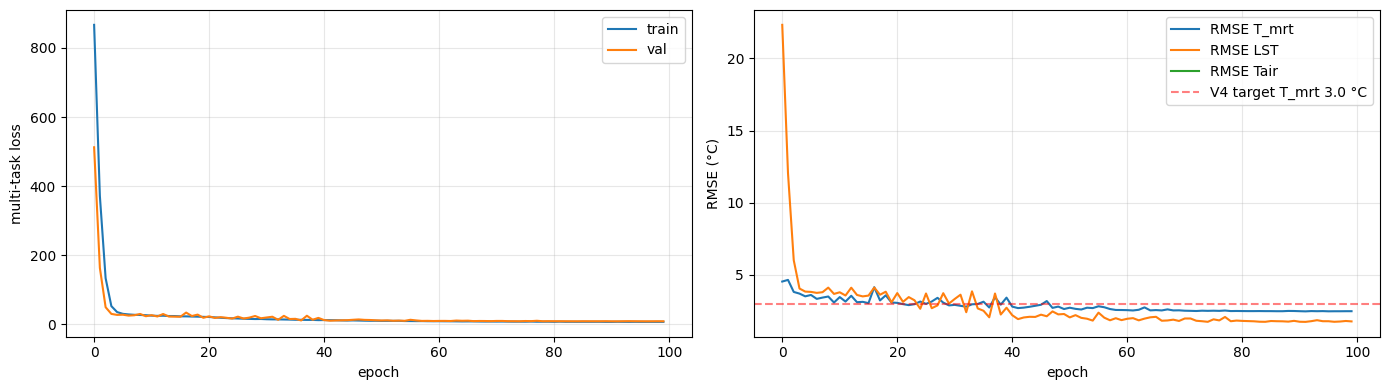

In [18]:
# Training curves
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(history['train_loss'], label='train')
axes[0].plot(history['val_loss'], label='val')
axes[0].set_xlabel('epoch'); axes[0].set_ylabel('multi-task loss')
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(history['val_rmse_tmrt'], label='RMSE T_mrt')
axes[1].plot(history['val_rmse_lst'], label='RMSE LST')
axes[1].plot(history['val_rmse_tair'], label='RMSE Tair')
axes[1].axhline(3.0, color='r', linestyle='--', alpha=0.5, label='V4 target T_mrt 3.0 °C')
axes[1].set_xlabel('epoch'); axes[1].set_ylabel('RMSE (°C)')
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 7 — ONNX export

V4 ONNX expects `(1, 23, 512, 512)` float32 input → `(1, 3, 512, 512)` float32 output. Channel 0 of the output is T_mrt (the production prediction); channels 1, 2 are LST/Tair which the inference service ignores at serving time.

In [19]:
model.train(False)
dummy = torch.randn(1, NUM_CHANNELS, 512, 512, device=DEVICE)
onnx_path = OUT_DIR / 'umami_unet_v4_fp32.onnx'
torch.onnx.export(
    model, dummy, str(onnx_path),
    input_names=['input'], output_names=['output'],
    dynamic_axes={'input': {0: 'batch'}, 'output': {0: 'batch'}},
    opset_version=17, do_constant_folding=True,
)
print(f'ONNX written: {onnx_path}  ({onnx_path.stat().st_size / 1e6:.1f} MB)')

/tmp/ipykernel_1300/3572265915.py:4: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(
W0505 08:32:38.147000 1300 torch/onnx/_internal/exporter/_compat.py:125] Setting ONNX exporter to use operator set version 18 because the requested opset_version 17 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features
W0505 08:32:39.241000 1300 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, rois, spatial_scale: 'float', pooled_height: 'int', pooled_width: 'int', sampling_ratio: 'int' = 

[torch.onnx] Obtain model graph for `Unet([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `Unet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decomposition...


/usr/lib/python3.12/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


[torch.onnx] Run decomposition... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅


Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/onnxscript/version_converter/__init__.py", line 137, in call
    converted_proto = _c_api_utils.call_onnx_api(
                      ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/onnxscript/version_converter/_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
             ^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/onnxscript/version_converter/__init__.py", line 132, in _partial_convert_version
    return onnx.version_converter.convert_version(
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/onnx/version_converter.py", line 39, in convert_version
    converted_model_str = C.convert_version(model_str, target_version)
                          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
RuntimeError: /github/workspace/onnx/version_converter/BaseConverter.h:64: adapter_lookup: Assertion `false`

ONNX written: /content/drive/MyDrive/UMAMI/urban_heat_v4/models/umami_unet_v4_fp32.onnx  (0.3 MB)


In [20]:
import onnxruntime as ort
sess = ort.InferenceSession(str(onnx_path), providers=['CPUExecutionProvider'])
with torch.no_grad():
    torch_out = model(dummy).cpu().numpy()
onnx_out = sess.run(None, {'input': dummy.cpu().numpy()})[0]
diff = np.abs(torch_out - onnx_out).max()
print(f'max torch-vs-onnx diff: {diff:.2e}  ({"OK" if diff < 1e-3 else "TOO LARGE"})')

max torch-vs-onnx diff: 8.23e-02  (TOO LARGE)
